# Bài kiểm tra 1 · Dự đoán giá nhà Ames

Xác định bài toán, khảo sát và tiền xử lý. Chưa huấn luyện mô hình ở mốc này.

Đơn vị mẫu: một giao dịch nhà ở. Đầu ra: `SalePrice` (USD), biến đổi `log1p` để dùng ở mốc sau. Đầu vào: 77 đặc trưng sau khi bỏ định danh và thông tin chốt giao dịch. Nguồn: [De Cock 2011](https://jse.amstat.org/v19n3/decock.pdf), [dữ liệu gốc](https://jse.amstat.org/v19n3/decock/AmesHousing.txt).

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists(), 'Mở notebook trong thư mục dự án'
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.preprocessing import load_raw, clean_features, make_preprocessor
from src.kt1 import run
summary = run()

{
  "rows": 2930,
  "columns": 82,
  "predictors": 77,
  "train_rows": 2589,
  "test_rows": 341,
  "encoded_features": 350,
  "numeric_features": 34,
  "categorical_features": 43,
  "duplicate_rows": 0,
  "duplicate_payload": 0,
  "duplicate_pid": 0,
  "raw_NA_tokens": 13278,
  "raw_NA_columns": 14,
  "raw_empty_cells": 719,
  "whitespace_cells": 2536,
  "invalid_years": {
    "Year Built": 1,
    "Year Remod/Add": 3,
    "Garage Yr Blt": 2
  },
  "train_missing": 648,
  "test_missing": 77,
  "target_min": 13100,
  "target_max": 755000,
  "target_mean": 181875.88837388952,
  "target_median": 161500.0,
  "skew_raw": 1.7376881930790997,
  "skew_log": 0.05542600814969582,
  "large_houses_train": 5,
  "correlations": {
    "Overall Qual": 0.802409093050676,
    "Gr Liv Area": 0.7093397639592312,
    "Garage Cars": 0.6482084562512422,
    "Year Built": 0.5556252780222584
  },
  "garage_correlation": 0.8880050565460976,
  "yearly_counts": {
    "2006": 625,
    "2007": 694,
    "2008": 622,


## 1 Phát biểu bài toán và tiêu chí thành công

Học có giám sát, hồi quy đa biến. Mô phỏng định giá trước khi giao dịch hoàn tất, tại Ames và cùng bối cảnh lịch sử 2006–2010. Không suy rộng trực tiếp sang Việt Nam hoặc giá hiện nay. Chỉ số chính dự kiến: RMSE của `log1p(SalePrice)`, mục tiêu ≤ 0,18 và giảm ít nhất 10% so với baseline học trên train. Chỉ số bổ trợ: MAE/RMSE theo USD và R². Đây là mục tiêu cho KT2, chưa phải kết quả thực nghiệm.

In [2]:
raw = load_raw(ROOT / 'data/raw/AmesHousing.tsv')
train = raw[raw['Yr Sold'] < 2010].copy()
test = raw[raw['Yr Sold'] == 2010].copy()
print('Toàn bộ:', raw.shape, 'Train:', train.shape, 'Test:', test.shape)
display(raw.head())
display(raw.groupby('Yr Sold').size().rename('Số nhà').to_frame())

Toàn bộ: (2930, 82) Train: (2589, 82) Test: (341, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,0526301100,020,RL,141,31770,Pave,NA,IR1,Lvl,...,0,NA,NA,NA,0,5,2010,WD,Normal,215000
1,2,0526350040,020,RH,80,11622,Pave,NA,Reg,Lvl,...,0,NA,MnPrv,NA,0,6,2010,WD,Normal,105000
2,3,0526351010,020,RL,81,14267,Pave,NA,IR1,Lvl,...,0,NA,NA,Gar2,12500,6,2010,WD,Normal,172000
3,4,0526353030,020,RL,93,11160,Pave,NA,Reg,Lvl,...,0,NA,NA,NA,0,4,2010,WD,Normal,244000
4,5,0527105010,060,RL,74,13830,Pave,NA,IR1,Lvl,...,0,NA,MnPrv,NA,0,3,2010,WD,Normal,189900


,Số nhà
Yr Sold,
2006,625
2007,694
2008,622
2009,648
2010,341


## 2 Nguồn và từ điển dữ liệu

82 cột gồm 1 nhãn, 2 định danh và 79 biến khác. Bỏ thêm `Sale Type`, `Sale Condition` vì có thể chỉ chắc chắn khi chốt giao dịch. Từ điển đủ 82 cột nằm ở `docs/data_dictionary.csv`; diễn giải các mã nằm ở `data/raw/DataDocumentation.txt`. Dữ liệu tải trực tiếp từ trang JSE, có checksum trong `reports/summary.json`. Không gán giấy phép mã nguồn cho dữ liệu bên thứ ba.

In [3]:
dictionary = pd.read_csv(ROOT / 'docs/data_dictionary.csv', keep_default_na=False)
display(dictionary)
assert dictionary['meaning_original'].ne('').all()

,column,raw_dtype,measurement,meaning_original,NA_count,role,treatment
0,Order,int64,Discrete,Observation number,0,excluded,excluded
1,PID,str,Nominal,Parcel identification number - can be used wi...,0,excluded,excluded
2,MS SubClass,str,Nominal,Identifies the type of dwelling involved in th...,0,predictor,one-hot; unknown NA imputed separately
3,MS Zoning,str,Nominal,Identifies the general zoning classification o...,0,predictor,one-hot; unknown NA imputed separately
4,Lot Frontage,str,Continuous,Linear feet of street connected to property,0,predictor,median + missing indicator + scale; area p99 clip
...,...,...,...,...,...,...,...
77,Mo Sold,int64,Discrete,Month Sold (MM),0,predictor,one-hot; unknown NA imputed separately
78,Yr Sold,int64,Discrete,Year Sold (YYYY),0,predictor,median + missing indicator + scale; area p99 clip
79,Sale Type,str,Nominal,Type of sale,0,excluded,excluded
80,Sale Condition,str,Nominal,Condition of sale,0,excluded,excluded


## 3 Thống kê mô tả trên tập huấn luyện

Chia theo thời gian trước EDA. Dữ liệu test chỉ được kiểm tra schema/chất lượng và transform; không dùng để lựa chọn chính sách xử lý hoặc siêu tham số.

In [4]:
x_train = clean_features(train)
x_test = clean_features(test)
display(x_train.describe().T)
display(x_train.describe(include=['object', 'str']).T)
display(train['SalePrice'].describe())

,count,mean,std,min,25%,50%,75%,max
Lot Frontage,2150.0,69.283721,23.518464,21.0,59.00,68.0,80.00,313.0
Lot Area,2589.0,10201.929316,8154.298746,1300.0,7441.00,9439.0,11600.00,215245.0
Overall Qual,2589.0,6.116647,1.418956,1.0,5.00,6.0,7.00,10.0
Overall Cond,2589.0,5.561221,1.102468,1.0,5.00,5.0,6.00,9.0
Year Built,2588.0,1971.579212,30.292906,1872.0,1954.00,1974.0,2001.00,2009.0
Year Remod/Add,2586.0,1984.278422,20.867618,1950.0,1965.00,1993.0,2004.00,2009.0
Mas Vnr Area,2567.0,103.896377,180.883424,0.0,0.00,0.0,168.00,1600.0
BsmtFin SF 1,2588.0,442.162287,459.061616,0.0,0.00,371.0,737.25,5644.0
BsmtFin SF 2,2588.0,48.782071,166.911420,0.0,0.00,0.0,0.00,1526.0
Bsmt Unf SF,2588.0,562.117465,441.438477,0.0,220.00,467.0,809.25,2336.0


,count,unique,top,freq
MS SubClass,2589,16,020,954
MS Zoning,2589,7,RL,2020
Street,2589,2,Pave,2580
Alley,2589,3,__ABSENT__,2411
Lot Shape,2589,4,Reg,1629
Land Contour,2589,4,Lvl,2322
Utilities,2589,3,AllPub,2586
Lot Config,2589,5,Inside,1899
Land Slope,2589,3,Gtl,2471
Neighborhood,2589,28,NAmes,385


count      2589.000000
mean     181875.888374
std       80504.708260
min       13100.000000
25%      129900.000000
50%      161500.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

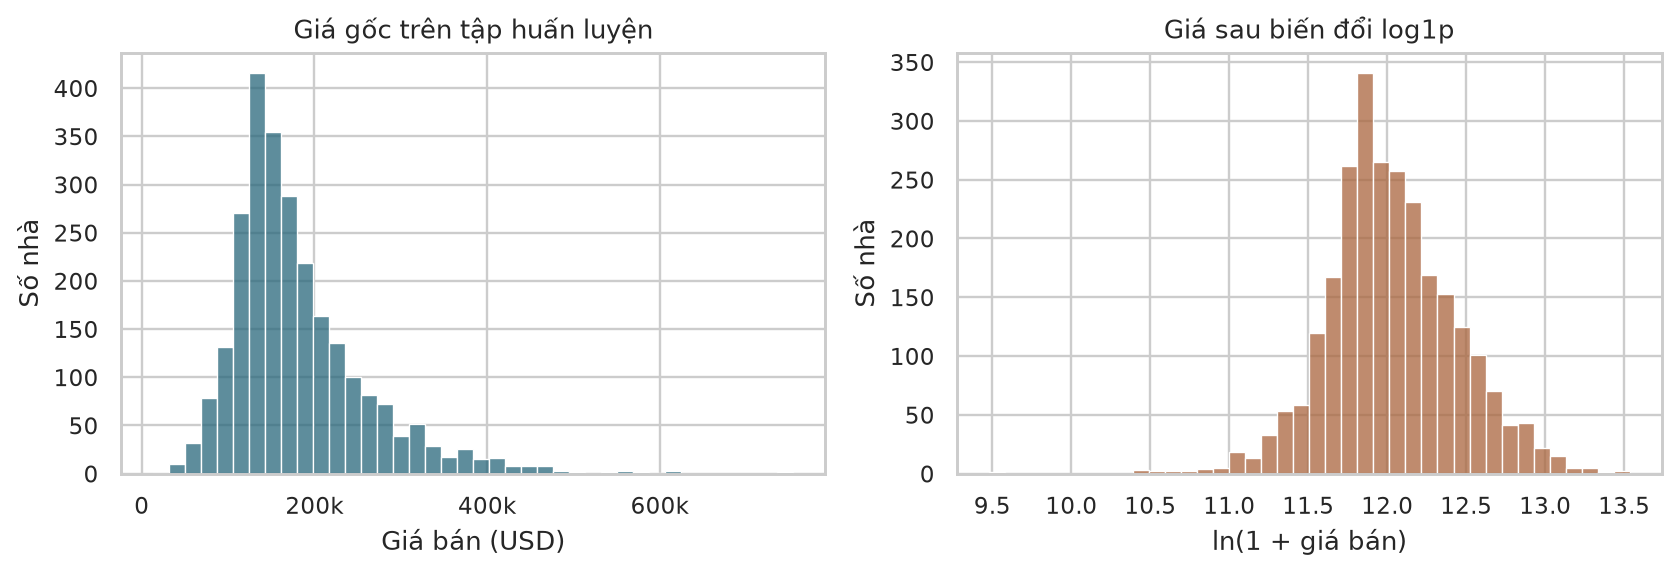

Độ lệch giá gốc: 1.7376881930790997 ; sau log1p: 0.05542600814969582


In [5]:
display(Image(filename=str(ROOT / 'reports/figures/01_target.png')))
print('Độ lệch giá gốc:', summary['skew_raw'], '; sau log1p:', summary['skew_log'])

Giá gốc có đuôi phải, trung bình cao hơn trung vị. Log1p giảm skew từ khoảng 1,738 xuống 0,055 trên train. Điều này hỗ trợ dùng mất mát trên log, nhưng không chứng minh phần dư mô hình sẽ chuẩn.

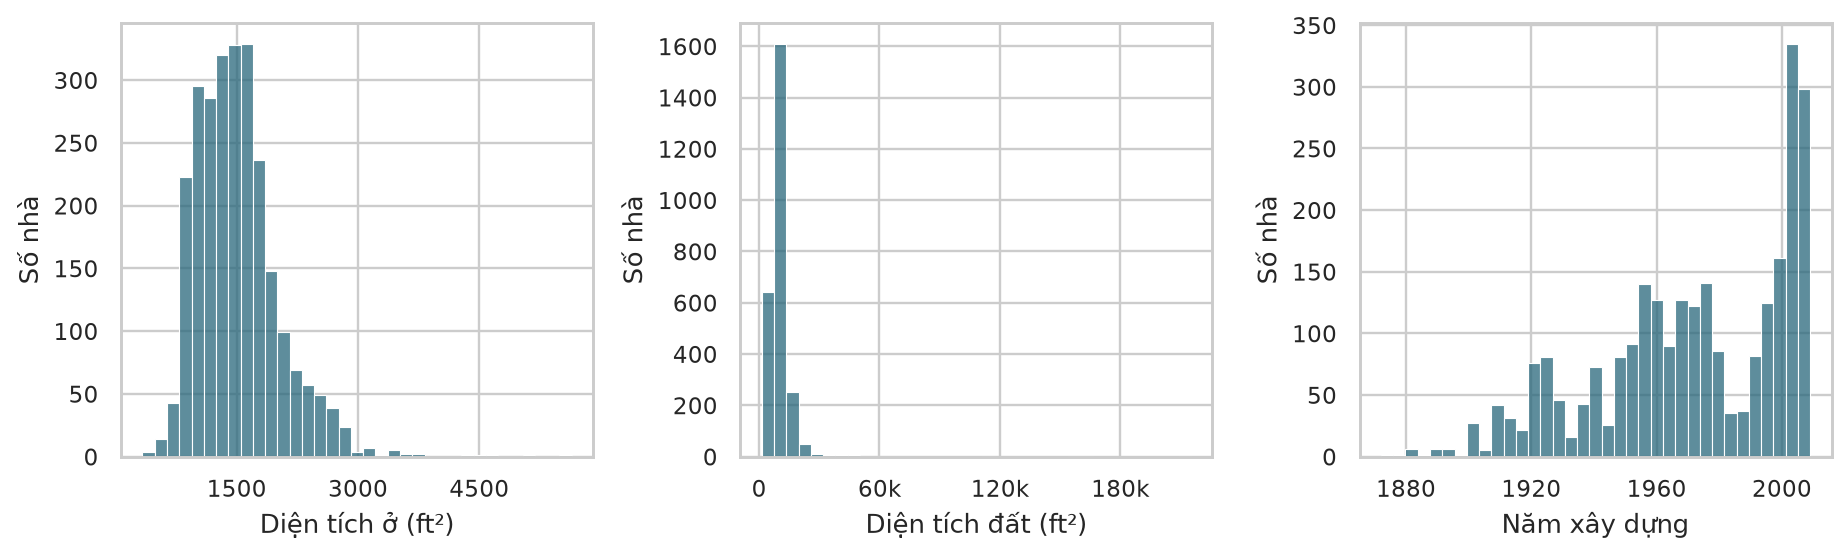

In [6]:
display(Image(filename=str(ROOT / 'reports/figures/02_features.png')))

Diện tích ở và diện tích đất lệch phải; ít lô rất lớn kéo dài trục. Năm xây dựng trải rộng nhiều thế hệ nhà, cần giữ như một biến riêng thay vì giả định giá chỉ do diện tích. Không xóa nhà lớn chỉ dựa trên kích thước.

## 4 Quan hệ đặc trưng và nhãn

,Unnamed: 0,SalePrice
0,Overall Qual,0.802409
1,Gr Liv Area,0.709340
2,Garage Cars,0.648208
3,Garage Area,0.642658
4,Total Bsmt SF,0.629203
5,1st Flr SF,0.619342
6,Year Built,0.555625
7,Full Bath,0.553012
8,Year Remod/Add,0.535093
9,Garage Yr Blt,0.529132


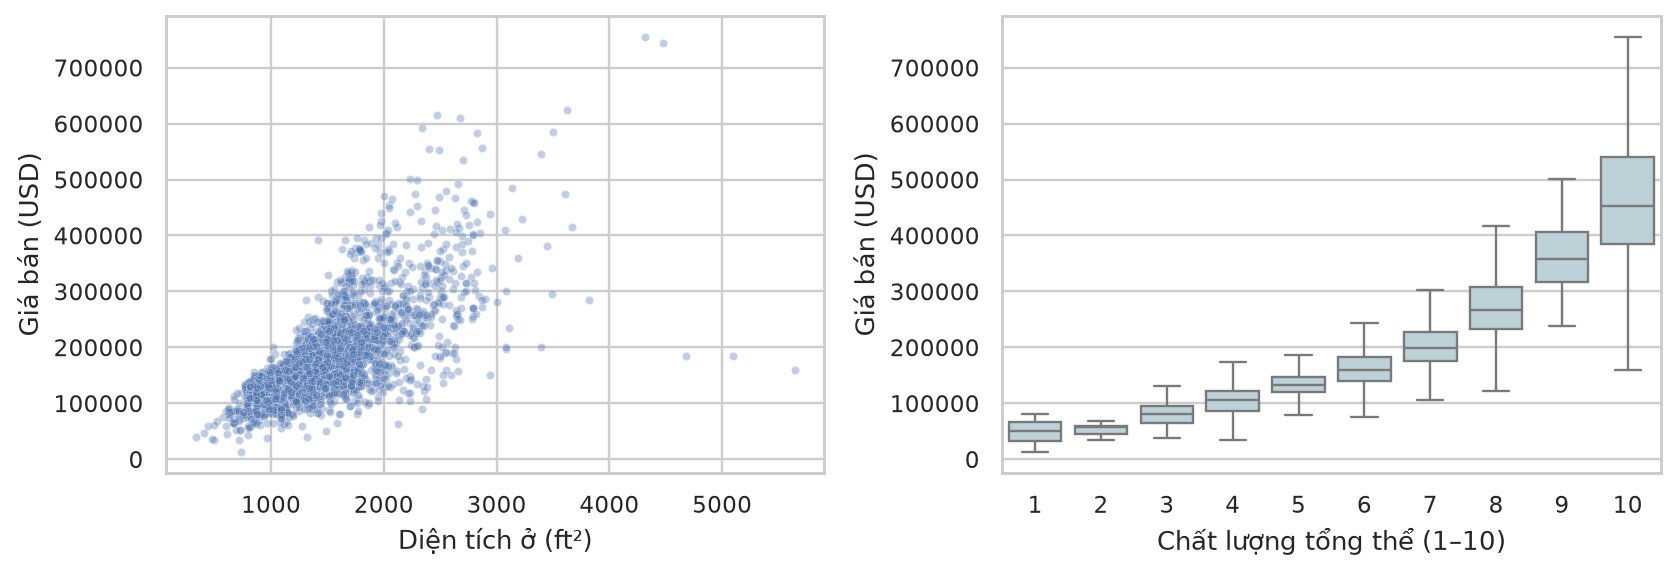

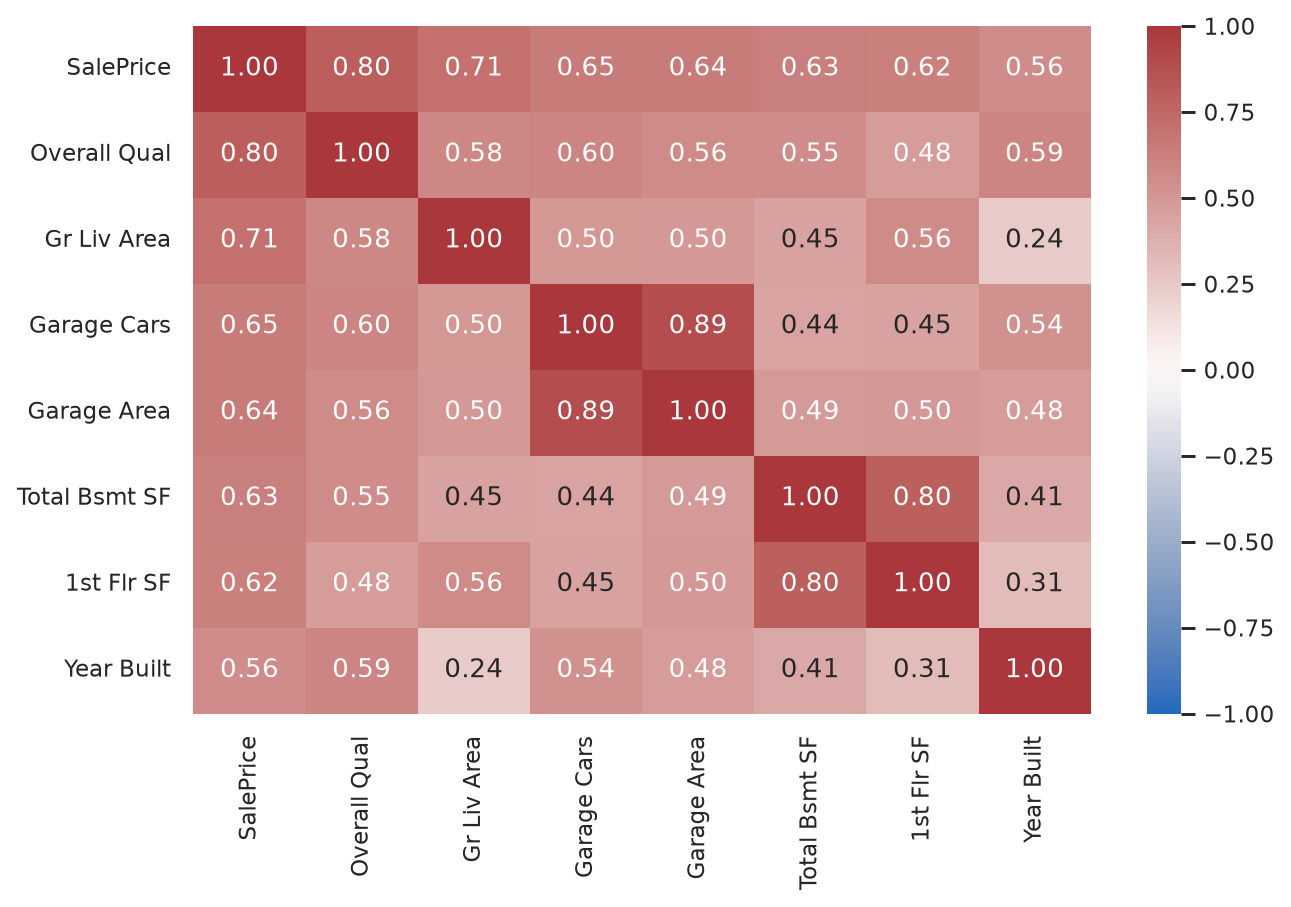

In [7]:
display(pd.read_csv(ROOT / 'reports/tables/target_correlations_train.csv').head(12))
display(Image(filename=str(ROOT / 'reports/figures/03_relationships.png')))
display(Image(filename=str(ROOT / 'reports/figures/04_correlations.png')))

Ba kết luận cho mô hình: (1) Overall Qual tương quan giá khoảng 0,802, nên giữ thông tin chất lượng; (2) Gr Liv Area tương quan khoảng 0,709 nhưng còn nhiều phân tán, cần thêm khu vực/chất lượng; (3) Garage Area và Garage Cars tương quan khoảng 0,888, tạo động cơ dùng chính quy hóa để ổn định hệ số. Đây là quan hệ thống kê, không phải tác động nhân quả.

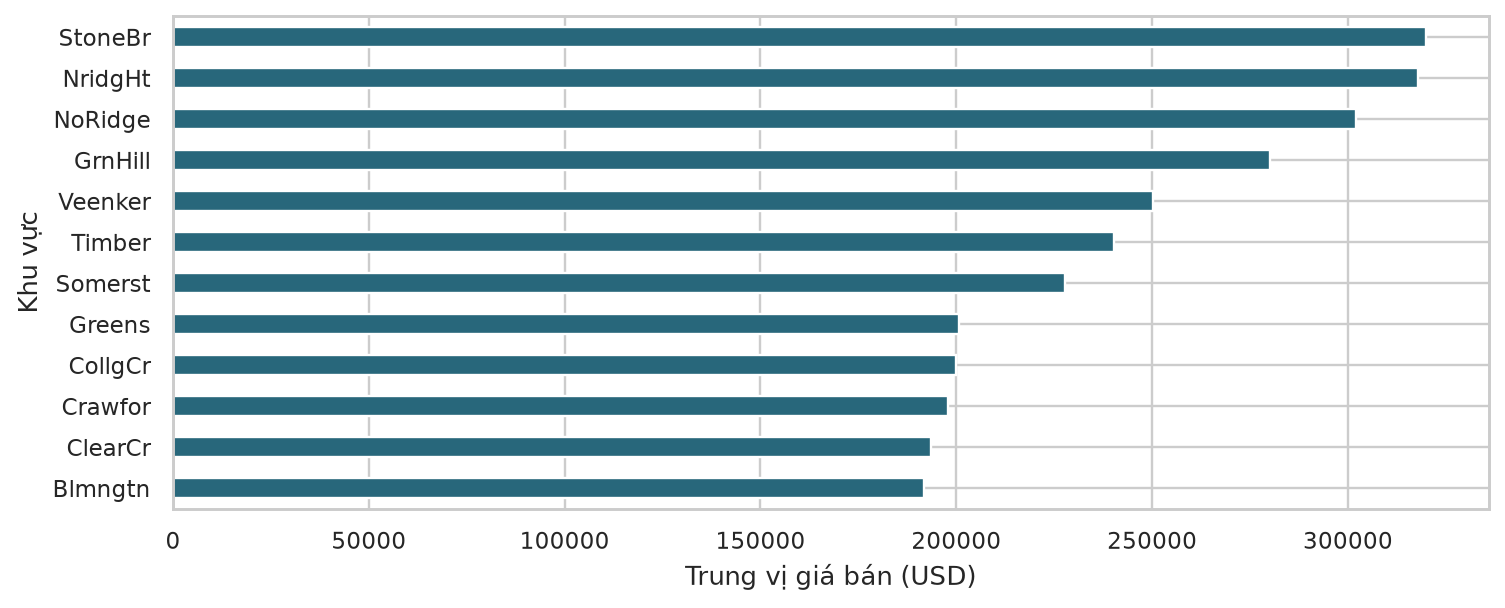

,size,median
Neighborhood,,
StoneBr,45,319900.0
NridgHt,151,318000.0
NoRidge,61,302000.0
GrnHill,2,280000.0
Veenker,24,250250.0
Timber,64,240250.0
Somerst,161,227680.0
Greens,6,200750.0
CollgCr,246,200000.0


In [8]:
display(Image(filename=str(ROOT / 'reports/figures/07_neighborhood.png')))
display(train.groupby('Neighborhood')['SalePrice'].agg(['size', 'median']).sort_values('median', ascending=False).head(12))

Trung vị giá thay đổi theo khu vực. One-hot giúp biểu diễn khác biệt vị trí; nhóm ít mẫu có thể có ước lượng kém ổn định. Không dùng trung vị giá từng khu vực tính trên toàn bộ dữ liệu để mã hóa đầu vào.

## 5 Kiểm tra chất lượng dữ liệu

,column,dtype_raw,NA_literal,empty,unique,NA_pct
4,Lot Frontage,str,0,490,129,0.000000
7,Alley,str,2732,0,3,93.242321
26,Mas Vnr Type,str,0,23,6,0.000000
27,Mas Vnr Area,str,0,23,446,0.000000
31,Bsmt Qual,str,79,1,7,2.696246
32,Bsmt Cond,str,79,1,7,2.696246
33,Bsmt Exposure,str,79,4,6,2.696246
34,BsmtFin Type 1,str,79,1,8,2.696246
35,BsmtFin SF 1,str,0,1,996,0.000000
36,BsmtFin Type 2,str,79,2,8,2.696246


Trùng nguyên dòng: 0
Trùng sau bỏ ID: 0
Trùng PID: 0
Năm vi phạm giả định: {'Year Built': 1, 'Year Remod/Add': 3, 'Garage Yr Blt': 2}
Ô có khoảng trắng thừa: 2536


,feature,q1,q3,iqr_flag_count
0,Lot Frontage,59.00,80.00,175
1,Lot Area,7441.00,11600.00,111
2,Overall Qual,5.00,7.00,4
3,Overall Cond,5.00,6.00,221
4,Year Built,1954.00,2001.00,8
5,Year Remod/Add,1965.00,2004.00,0
6,Mas Vnr Area,0.00,168.00,171
7,BsmtFin SF 1,0.00,737.25,13
8,BsmtFin SF 2,0.00,0.00,305
9,Bsmt Unf SF,220.00,809.25,44


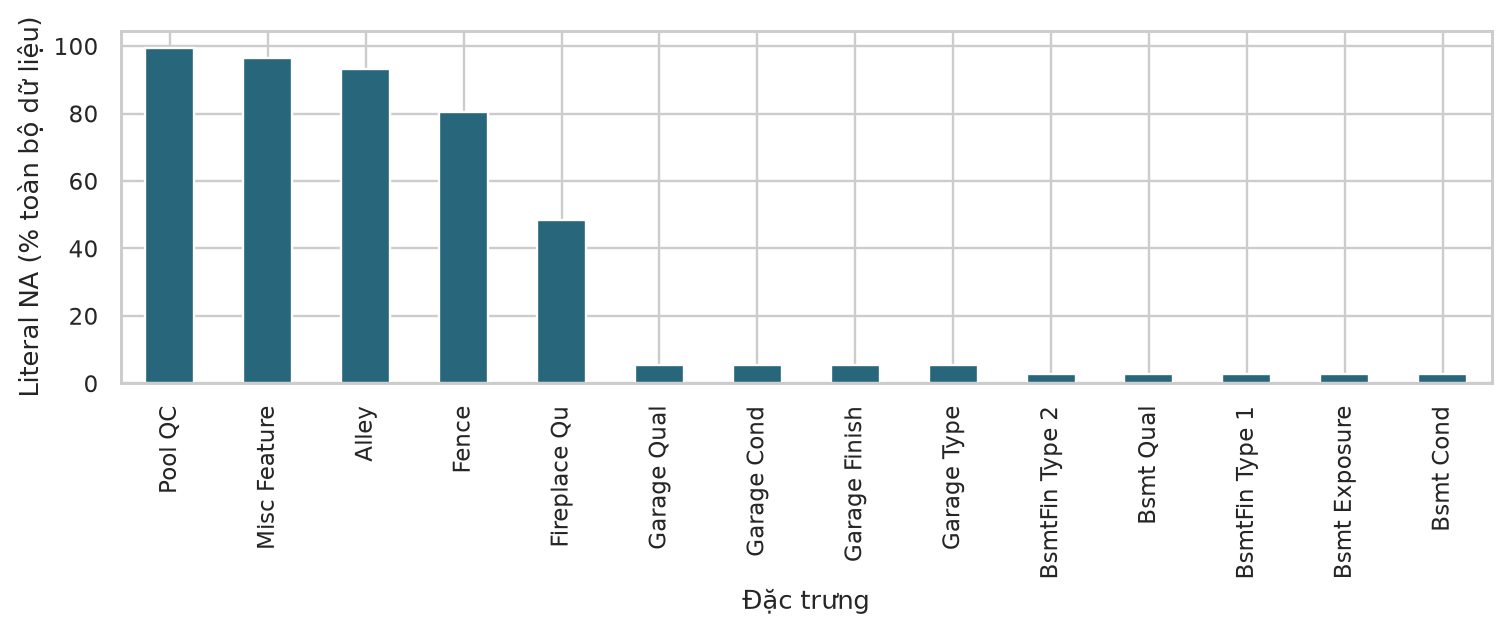

In [9]:
q = pd.read_csv(ROOT / 'reports/tables/quality_all_columns.csv')
display(q[(q['NA_literal'] > 0) | (q['empty'] > 0)])
print('Trùng nguyên dòng:', summary['duplicate_rows'])
print('Trùng sau bỏ ID:', summary['duplicate_payload'])
print('Trùng PID:', summary['duplicate_pid'])
print('Năm vi phạm giả định:', summary['invalid_years'])
print('Ô có khoảng trắng thừa:', summary['whitespace_cells'])
display(pd.read_csv(ROOT / 'reports/tables/outliers_iqr_train.csv'))
display(Image(filename=str(ROOT / 'reports/figures/05_na_tokens.png')))

Có 719 ô trống thực sự và 13.278 mã NA biểu diễn không có tiện ích theo từ điển. Không gộp hai nhóm thành thiếu. Có 6 ô năm vi phạm giả định năm xây/cải tạo/garage không vượt năm bán; chuyển thành thiếu để điền median train. Không có trùng PID hay trùng bản ghi. Với hồi quy, mất cân bằng lớp không áp dụng; đuôi giá cao ít mẫu là vấn đề tương ứng cần phân tích lỗi ở KT2.

## 6 Tiền xử lý và so sánh trước sau

Strip chuỗi, giữ None hợp lệ; NA tiện ích thành `__ABSENT__`; các ô thiếu khác điền riêng. Cột số: clip các cột diện tích/giá trị về [0,p99 train], median có cờ thiếu, StandardScaler. Cột phân loại: điền `__MISSING__`, one-hot với `handle_unknown=ignore`. MS SubClass và tháng bán là phân loại. Không clip/xóa nhãn giá.

,stage,rows,columns,missing_cells
0,Train sau quy tắc ngữ nghĩa,2589,77,648
1,Test sau quy tắc ngữ nghĩa,341,77,77
2,Train sau pipeline,2589,350,0
3,Test sau pipeline,341,350,0


,feature,upper_train_p99,changed_train,changed_test
0,Lot Frontage,134.51,22,4
1,Lot Area,34063.04,26,2
2,Mas Vnr Area,777.44,26,2
3,BsmtFin SF 1,1636.52,26,3
4,BsmtFin SF 2,869.39,26,6
5,Bsmt Unf SF,1779.34,26,3
6,Total Bsmt SF,2209.04,26,2
7,1st Flr SF,2340.88,26,2
8,2nd Flr SF,1402.36,26,3
9,Low Qual Fin SF,205.00,25,2


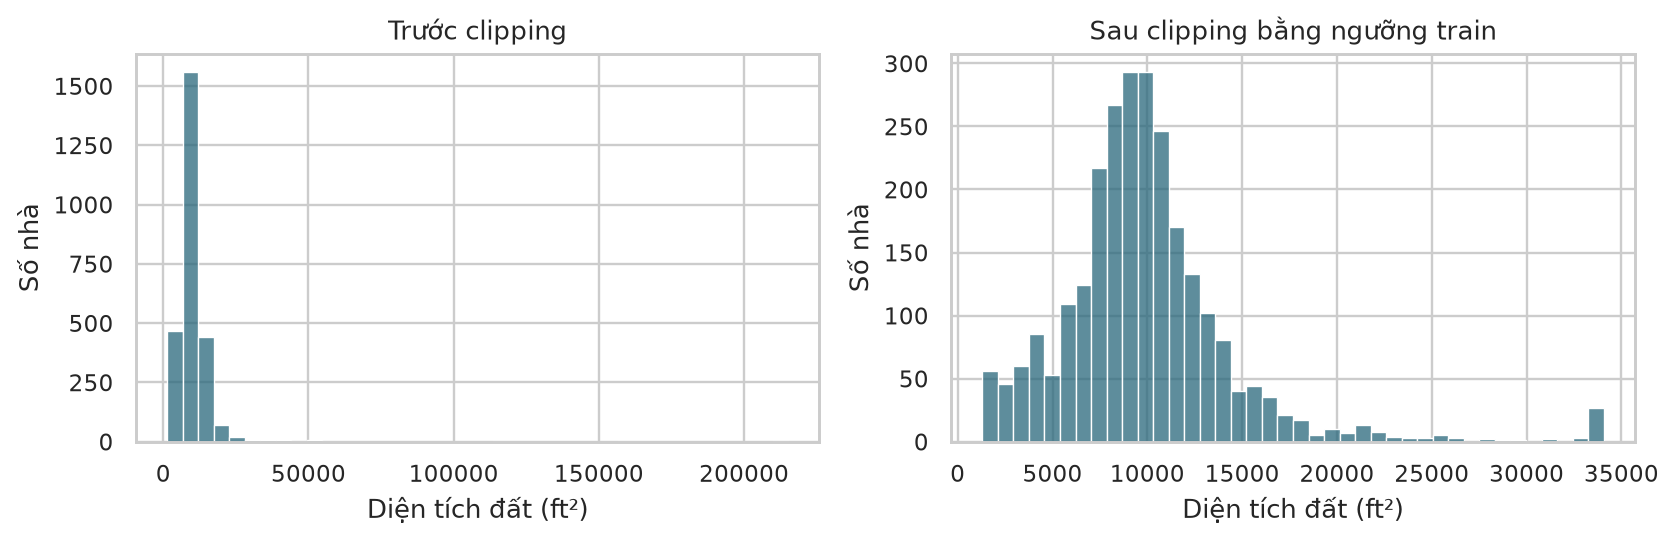

In [10]:
preprocessor = make_preprocessor(x_train)
X_train = preprocessor.fit_transform(x_train)
X_test = preprocessor.transform(x_test)
y_train_log = np.log1p(train['SalePrice'])
y_test_log = np.log1p(test['SalePrice'])
display(pd.read_csv(ROOT / 'reports/tables/before_after.csv'))
display(pd.read_csv(ROOT / 'reports/tables/clipping_audit.csv'))
display(Image(filename=str(ROOT / 'reports/figures/06_before_after.png')))

Clipping giảm đuôi diện tích đất nhưng làm mất một phần khác biệt giữa các lô rất lớn. Đây là cấu hình khởi đầu, cần so sánh có/không clipping trên CV ở mốc sau. Giữ nguyên số dòng; chưa khẳng định cấu hình này tối ưu.

In [11]:
assert X_train.shape[0] == 2589 and X_test.shape[0] == 341
assert X_train.shape[1] == X_test.shape[1]
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert set(train['PID']).isdisjoint(set(test['PID']))
assert not set(['SalePrice','PID','Order','Sale Type','Sale Condition']) & set(x_train)
print('Kiểm tra dữ liệu sẵn sàng:', X_train.shape, X_test.shape)

Kiểm tra dữ liệu sẵn sàng: (2589, 350) (341, 350)


## 7 Chiến lược đánh giá cho KT2

Test năm 2010 được giữ lại. Trên train, dùng ba fold mở rộng theo năm: học 2006 → kiểm định 2007; học 2006–2007 → kiểm định 2008; học 2006–2008 → kiểm định 2009. Mỗi fold phải fit lại clipping, imputer, scaler và encoder. Không tái sử dụng file ma trận đã fit cả train để tính CV. Có thể dùng RidgeCV/LassoCV như thử nghiệm bổ sung, nhưng CV nội bộ sau preprocessing fit toàn bộ train vẫn gây rò rỉ giữa fold. So sánh alpha bằng vòng ngoài fit lại toàn pipeline, đánh giá theo cùng RMSE log. Báo cáo mean/std và từng fold; số fold ít là hạn chế.

In [12]:
folds = []
for year in [2007, 2008, 2009]:
    fit_idx = np.flatnonzero(train['Yr Sold'].to_numpy() < year)
    val_idx = np.flatnonzero(train['Yr Sold'].to_numpy() == year)
    assert train.iloc[fit_idx]['Yr Sold'].max() < train.iloc[val_idx]['Yr Sold'].min()
    folds.append((fit_idx, val_idx))
    print('Validation year', year, '| train', len(fit_idx), '| validation', len(val_idx))

Validation year 2007 | train 625 | validation 694
Validation year 2008 | train 1319 | validation 622
Validation year 2009 | train 1941 | validation 648


## 8 Lý thuyết chính quy hóa và phạm vi tiếp theo

Với mục tiêu z=ln(1+y), hàm mất mát chung: $J=\frac{1}{2n}\|z-b-Xw\|_2^2+\alpha[\rho\|w\|_1+\frac{1-\rho}{2}\|w\|_2^2]$. Lasso: ρ=1; L2: ρ=0; Elastic Net: 0<ρ<1. Alpha kiểm soát mức phạt, tăng alpha làm hệ số co mạnh hơn; intercept thường không bị phạt. L1 có thể tạo hệ số đúng bằng 0, L2 thường co liên tục. Quy ước alpha của Ridge trong sklearn có hệ số chuẩn hóa khác Lasso/ElasticNet, không so trực tiếp cùng giá trị số. Xem báo cáo Word cho phần giải thích. KT1 chưa chọn alpha hoặc tuyên bố mô hình thắng.

## 9 Thực hành cá nhân và minh bạch

Thực hành đổi đặc trưng vẽ biểu đồ, thống kê số thiếu và đổi median sang mean theo `docs/ON_TAP_VAN_DAP.md`. Đối chiếu đủ 10 tiêu chí tại `docs/DOI_CHIEU_TIEU_CHI.md`. AI hỗ trợ tìm nguồn, soạn mã, EDA và báo cáo. Sinh viên cần bổ sung thông tin cá nhân, tự kiểm tra và ghi nhận phần việc thực sự tại `docs/NHAT_KY_DONG_GOP.md`; không coi commit tạo tự động là minh chứng sinh viên đã tự thực hiện.